# Experiment 7: Layer 5 resolution sensitivity 

Layer 5 till now has been solved on a grid of at most `MAX_NODES = 2500` pixels and stretched back to the crop size. The median crop is about 111 px wide, so most crops are shrunk about 2x and the largest about 5x. Our central negative results is that the full method scores about 0.05 Dice below a plan fill between the same seeds. This notebook answers whether layer 5 was handicapped by running at this resolution.

| Grid limit | Meaning |
| --- | --- |
| 2,500 | the main setting of Notebooks 4-10 |
| 10,000 | about 100 x 100 |
| 65,536 | no downscaling for any crop (the largest crop is 256 x 256) |

## State restoration

In [ ]:
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve, cg, LinearOperator
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED)
LAP_WINDOW, LAP_EPSILON, MU_GRID, N_BOOT = 3, 1e-7, [0.1, 1.0, 10.0], 2000
TAUS = (2, 5, 10)
GRID_LIMITS = [2500, 10000, 65536]
MU_FIXED = 1.0
print("Config loaded.")

Mounted at /content/drive
Config loaded.


In [2]:
final_df_loaded = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
roi_arch    = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz"))
gtmask_arch = np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
prob_arch   = np.load(os.path.join(OUTPUTS_DIR, "layer4_prob_maps.npz"))
class_of   = dict(zip(final_df_loaded['image_id'], final_df_loaded['class']))
patient_of = dict(zip(final_df_loaded['image_id'], final_df_loaded['patient_id']))
preprocessed_results = {iid: {'roi': roi_arch[iid], 'gt_mask': gtmask_arch[iid] if iid in gtmask_arch.files else None,
                              'class': class_of.get(iid), 'patient_id': patient_of.get(iid)} for iid in roi_arch.files}
sp = json.load(open(os.path.join(RESULTS_DIR, "train_test_split.json")))
train_ids, val_ids, test_ids = set(sp['train_ids']), set(sp['val_ids']), set(sp['test_ids'])
layer4_maps = {iid: prob_arch[iid] for iid in prob_arch.files}
l4 = json.load(open(os.path.join(RESULTS_DIR, "layer4_map_ids.json")))
EVAL_VAL  = sorted(i for i in l4['val_ids']  if preprocessed_results.get(i, {}).get('gt_mask') is not None)
EVAL_TEST = sorted(i for i in l4['test_ids'] if preprocessed_results.get(i, {}).get('gt_mask') is not None)
assert not (set(EVAL_VAL) & train_ids) and not (set(EVAL_TEST) & (train_ids | val_ids)), "split leakage"
print(f"{len(EVAL_VAL)} validation and {len(EVAL_TEST)} test images")
os.makedirs(FIGURES_DIR, exist_ok=True)

156 validation and 269 test images


## Layer 5, baselines and metrics

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):     
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9, "vectorised Laplacian differs from v1"
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                     
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                             
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")
VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)   

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


## Evaluation seeds, surface Dice, and the fast Layer 5 solver

In [ ]:
def prep(iid):
    prob = layer4_maps[iid].astype(np.float32); h, w = prob.shape
    gt = preprocessed_results[iid]['gt_mask']
    if gt.shape != prob.shape: gt = cv2.resize(gt, (w, h), interpolation=cv2.INTER_NEAREST)
    roi = preprocessed_results[iid]['roi']
    if roi.shape != prob.shape: roi = cv2.resize(roi, (w, h), interpolation=cv2.INTER_LINEAR)
    return prob, roi, gt > 127
CACHE = {i: prep(i) for i in EVAL_VAL + EVAL_TEST}

K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break
        out = nxt
    return out
def make_eval_trimap(gt_bool, erode=TRIMAP_ERODE_ITERS, dilate=TRIMAP_DILATE_ITERS):
    mask = gt_bool.astype(np.uint8); tm = np.full(mask.shape, 128, np.uint8)
    tm[cv2.dilate(mask, K3, iterations=dilate) == 0] = 0
    tm[_erode_capped(mask, erode) == 1] = 255
    return tm
TRIMAPS = {i: make_eval_trimap(CACHE[i][2]) for i in CACHE}

def surface_dice(pred, gt, taus=TAUS):
    if pred.sum() == 0 or gt.sum() == 0: return {t: np.nan for t in taus}
    pb, gb = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    if pb.sum() == 0 or gb.sum() == 0: return {t: np.nan for t in taus}
    d_to_g, d_to_p = distance_transform_edt(~gb), distance_transform_edt(~pb)
    tot = pb.sum() + gb.sum()
    return {t: float(((d_to_g[pb] <= t).sum() + (d_to_p[gb] <= t).sum()) / tot) for t in taus}

def eval_one(iid, alpha):
    _, _, gt = CACHE[iid]; d = preprocessed_results[iid]
    if alpha.shape != gt.shape: alpha = cv2.resize(alpha, (gt.shape[1], gt.shape[0]), interpolation=cv2.INTER_LINEAR)
    pred = alpha >= ALPHA_THRESHOLD
    row = {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
           'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt), 'hd95': hd95(pred, gt),
           'alpha_mae': alpha_mae(alpha, gt)}
    row.update({f'sdice{t}': v for t, v in surface_dice(pred, gt).items()})
    return row
def eval_alphas(alphas): return pd.DataFrame([eval_one(i, a) for i, a in alphas.items()])

def _solve_spd(A, b, x0):
    d = A.diagonal(); Minv = LinearOperator(A.shape, matvec=lambda v: v / d, dtype=np.float64)
    try:
        x, info = cg(A, b, x0=x0, rtol=1e-9, atol=0.0, maxiter=5000, M=Minv)
    except TypeError:                                                  
        x, info = cg(A, b, x0=x0, tol=1e-9, maxiter=5000, M=Minv)
    if info != 0: x = spsolve(A.tocsc(), b)                            
    return x, info

def solve_alpha_multi(prob_map, trimap, roi, mus, max_nodes, lam=LAMBDA_PROPAGATION, gamma=GAMMA, use_cg=True):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR) if (hs, ws) != (h0, w0) else prob_map
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR) if (hs, ws) != (h0, w0) else roi
    tm_s   = _downscale_trimap(trimap, hs, ws) if (hs, ws) != (h0, w0) else trimap
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)
    L = build_matting_laplacian(roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    base_A = L + lam * diags(known); base_b = lam * known * target
    w_int = 1 - gamma
    a0 = ((1 - w_int) * prob_s + w_int * inten).ravel().astype(np.float64)
    out = {}
    for mu in mus:
        A = (base_A + mu * identity(len(a0), format='csr')).tocsr(); b = base_b + mu * a0
        x = _solve_spd(A, b, a0)[0] if use_cg else spsolve(A.tocsc(), b)
        a = np.clip(x.reshape(hs, ws), 0, 1).astype(np.float32)
        out[mu] = cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32) if (hs, ws) != (h0, w0) else a
    return out
print("Solver ready.")

Solver ready.


## Solver check 

Before anything is scored, the conjugate-gradient solver must reproduce the direct solver at the 2,500-pixel grid.

In [6]:
chk_ids = EVAL_TEST[::max(1, len(EVAL_TEST) // 20)][:20]
diffs, dd = [], []
for iid in chk_ids:
    prob, roi, gt = CACHE[iid]; tm = TRIMAPS[iid]
    ref = solve_alpha(prob, tm, roi, VARIANTS['paper_hybrid_mu1'], max_nodes=2500)
    new = solve_alpha_multi(prob, tm, roi, [1.0], 2500)[1.0]
    diffs.append(float(np.abs(ref - new).max())); dd.append(abs(dice(ref >= ALPHA_THRESHOLD, gt) - dice(new >= ALPHA_THRESHOLD, gt)))
print(f"{len(chk_ids)} test images: max |alpha_direct - alpha_CG| = {max(diffs):.2e}, max Dice difference = {max(dd):.2e}")
assert max(diffs) < 1e-3 and max(dd) < 1e-3, "conjugate-gradient solver does not reproduce the direct solver"
t0 = time.time(); big = max(chk_ids, key=lambda i: CACHE[i][0].size)
_ = solve_alpha_multi(CACHE[big][0], TRIMAPS[big], CACHE[big][1], MU_GRID, 65536)
print(f"largest check image {CACHE[big][0].shape}: three mu at native grid in {time.time() - t0:.1f} s")

20 test images: max |alpha_direct - alpha_CG| = 1.19e-07, max Dice difference = 0.00e+00
largest check image (188, 256): three mu at native grid in 1.2 s


## Validation: choose mu at each grid limit, and run every image

The Laplacian is built once per image and grid; the seed-only fill is solved on the same grid. Validation images select mu; test images are only scored.

In [ ]:
t0 = time.time()
ALPHA = {}                                   
VAL_TAB = []
for lim in GRID_LIMITS:
    store = {'seed': {}, **{mu: {} for mu in MU_GRID}}
    for split, ids in (('val', EVAL_VAL), ('test', EVAL_TEST)):
        store = {'seed': {}, **{mu: {} for mu in MU_GRID}}
        for iid in tqdm(ids, desc=f"grid {lim:>6} {split}"):
            prob, roi, _ = CACHE[iid]; tm = TRIMAPS[iid]
            store['seed'][iid] = trimap_only_on_grid(tm, 'distance', max_nodes=lim)
            res = solve_alpha_multi(prob, tm, roi, MU_GRID, lim)
            for mu in MU_GRID: store[mu][iid] = res[mu]
        ALPHA[(lim, split)] = store
    # choose mu on validation Dice
    vd = {mu: float(np.nanmean([dice(ALPHA[(lim, 'val')][mu][i] >= ALPHA_THRESHOLD, CACHE[i][2]) for i in EVAL_VAL])) for mu in MU_GRID}
    vseed = float(np.nanmean([dice(ALPHA[(lim, 'val')]['seed'][i] >= ALPHA_THRESHOLD, CACHE[i][2]) for i in EVAL_VAL]))
    for mu in MU_GRID: VAL_TAB.append({'grid_limit': lim, 'mu': mu, 'val_dice': vd[mu], 'val_dice_seed_only': vseed})
    print(f"limit {lim:>6}: val Dice by mu {{{', '.join(f'{m:g}: {v:.4f}' for m, v in vd.items())}}} | seed-only {vseed:.4f}")
val_tab = pd.DataFrame(VAL_TAB); val_tab.to_csv(os.path.join(RESULTS_DIR, "nb11_validation_mu_selection.csv"), index=False)
MU_SEL = {lim: val_tab[val_tab.grid_limit == lim].sort_values('val_dice', ascending=False).iloc[0]['mu'] for lim in GRID_LIMITS}
print("selected mu per grid limit:", {k: float(v) for k, v in MU_SEL.items()}, f"| {(time.time()-t0)/60:.1f} min")

grid   2500 test: 100%|██████████| 269/269 [00:15<00:00, 17.26it/s]


limit   2500: val Dice by mu {0.1: 0.6014, 1: 0.7438, 10: 0.5754} | seed-only 0.8022


grid  10000 test: 100%|██████████| 269/269 [00:31<00:00,  8.55it/s]


limit  10000: val Dice by mu {0.1: 0.7403, 1: 0.6736, 10: 0.5001} | seed-only 0.8108


grid  65536 test: 100%|██████████| 269/269 [01:10<00:00,  3.81it/s]


limit  65536: val Dice by mu {0.1: 0.7449, 1: 0.6573, 10: 0.4867} | seed-only 0.8113
selected mu per grid limit: {2500: 1.0, 10000: 0.1, 65536: 0.1} | 3.0 min


## Test split

In [8]:
DF = {}
for lim in GRID_LIMITS:
    A = ALPHA[(lim, 'test')]
    DF[(lim, 'seed-only fill')]            = eval_alphas(A['seed'])
    DF[(lim, 'full method, mu selected')]  = eval_alphas(A[MU_SEL[lim]])
    DF[(lim, f'full method, mu = {MU_FIXED:g}')] = eval_alphas(A[MU_FIXED])
METHODS = ['seed-only fill', 'full method, mu selected', f'full method, mu = {MU_FIXED:g}']
cols = ['dice', 'sensitivity', 'specificity', 'hd95', 'sdice2', 'sdice5', 'sdice10']
tab = pd.DataFrame([{'grid_limit': lim, 'method': m, 'n': len(DF[(lim, m)]), **{c: DF[(lim, m)][c].mean() for c in cols}}
                    for lim in GRID_LIMITS for m in METHODS])
tab.to_csv(os.path.join(RESULTS_DIR, "nb11_resolution_table.csv"), index=False)
print("TEST SPLIT (mean over images; HD95 in crop pixels; sdice = surface Dice within 2/5/10 px)")
print(tab.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
pd.concat([DF[(l, m)].assign(grid_limit=l, method=m) for l in GRID_LIMITS for m in METHODS]).to_csv(
    os.path.join(RESULTS_DIR, "nb11_per_image.csv"), index=False)

rows = []
for lim in GRID_LIMITS:
    for a, b in [('full method, mu selected', 'seed-only fill'), (f'full method, mu = {MU_FIXED:g}', 'seed-only fill')]:
        for metric in ('dice', 'sdice2', 'sdice5', 'hd95'):
            m_, lo, hi, n = paired_bootstrap(DF[(lim, a)], DF[(lim, b)], metric)
            rows.append({'grid_limit': lim, 'A': a, 'B': b, 'metric': metric, 'mean_diff_A_minus_B': m_, 'ci_low': lo, 'ci_high': hi, 'n': n})
for m in ('seed-only fill', 'full method, mu selected'):
    for lim in GRID_LIMITS[1:]:
        for metric in ('dice', 'sdice2'):
            m_, lo, hi, n = paired_bootstrap(DF[(lim, m)], DF[(GRID_LIMITS[0], m)], metric)
            rows.append({'grid_limit': lim, 'A': f'{m} @ {lim}', 'B': f'{m} @ {GRID_LIMITS[0]}', 'metric': metric,
                         'mean_diff_A_minus_B': m_, 'ci_low': lo, 'ci_high': hi, 'n': n})
cmp_df = pd.DataFrame(rows); cmp_df.to_csv(os.path.join(RESULTS_DIR, "nb11_comparisons_ci.csv"), index=False)
print("\nPAIRED DIFFERENCES (A minus B). Dice / surface Dice: positive = A better. HD95: negative = A better.")
print(cmp_df.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

print("\nDECLARED READING RULE: robust if (full, mu selected) - (seed-only) has a CI entirely below 0 in Dice at every grid limit")
verdict = {}
for lim in GRID_LIMITS:
    r = cmp_df[(cmp_df.grid_limit == lim) & (cmp_df.A == 'full method, mu selected') & (cmp_df.B == 'seed-only fill') & (cmp_df.metric == 'dice')].iloc[0]
    verdict[lim] = {'diff': r['mean_diff_A_minus_B'], 'ci': [r['ci_low'], r['ci_high']], 'below_zero': bool(r['ci_high'] < 0)}
    print(f"  limit {lim:>6}: {r['mean_diff_A_minus_B']:+.4f} [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]  -> {'below 0' if r['ci_high'] < 0 else 'NOT below 0'}")
ROBUST = all(v['below_zero'] for v in verdict.values())
ABOVE = all(v['ci'][0] > 0 for v in verdict.values())
CONCL = ("ROBUST: the full method is below the seed-only fill at every grid limit." if ROBUST else
         "REVERSED: the full method is above the seed-only fill at every grid limit; the main negative conclusion does not hold." if ABOVE else
         "NOT ROBUST: the sign or significance of the difference changes with the grid limit; the conclusion depends on the grid.")
print("\nCONCLUSION:", CONCL)
json.dump({'selected_mu': {str(k): float(v) for k, v in MU_SEL.items()}, 'verdict': {str(k): v for k, v in verdict.items()}, 'robust': ROBUST, 'reversed': ABOVE, 'conclusion': CONCL},
          open(os.path.join(RESULTS_DIR, "nb11_verdict.json"), 'w'), indent=2, default=float)

TEST SPLIT (mean over images; HD95 in crop pixels; sdice = surface Dice within 2/5/10 px)
 grid_limit                   method   n   dice  sensitivity  specificity   hd95  sdice2  sdice5  sdice10
       2500           seed-only fill 269 0.8009       0.9415       0.9883 4.0675  0.6337  0.9810   0.9985
       2500 full method, mu selected 269 0.7511       0.7722       0.9913 5.0733  0.6338  0.9449   0.9939
       2500      full method, mu = 1 269 0.7511       0.7722       0.9913 5.0733  0.6338  0.9449   0.9939
      10000           seed-only fill 269 0.8055       0.9681       0.9879 3.3805  0.6638  0.9919   0.9994
      10000 full method, mu selected 269 0.7706       0.7626       0.9934 4.3797  0.7308  0.9642   0.9958
      10000      full method, mu = 1 269 0.6685       0.8774       0.9768 5.9674  0.3900  0.8765   0.9978
      65536           seed-only fill 269 0.8063       0.9717       0.9877 3.1585  0.7178  0.9935   0.9995
      65536 full method, mu selected 269 0.7735       0.7710  

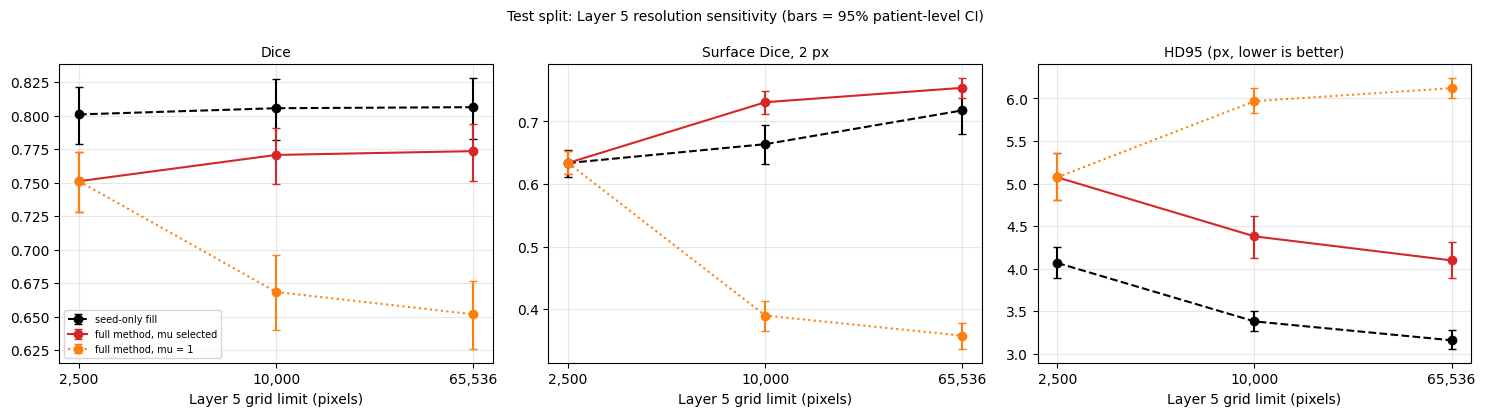

In [9]:
def boot_ci(df, col, n_boot=N_BOOT, seed=SEED):
    g = df.dropna(subset=[col]).groupby('patient_id')[col].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy(); rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g))); b = s[ix].sum(1) / c[ix].sum(1)
    return df[col].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sty = {'seed-only fill': ('k', '--'), 'full method, mu selected': ('tab:red', '-'), f'full method, mu = {MU_FIXED:g}': ('tab:orange', ':')}
x = np.arange(len(GRID_LIMITS))
for k, (col, ttl) in enumerate([('dice', 'Dice'), ('sdice2', 'Surface Dice, 2 px'), ('hd95', 'HD95 (px, lower is better)')]):
    for m, (c, ls) in sty.items():
        v = [boot_ci(DF[(l, m)], col) for l in GRID_LIMITS]
        ax[k].errorbar(x, [a[0] for a in v], yerr=[[a[0] - a[1] for a in v], [a[2] - a[0] for a in v]], color=c, ls=ls, marker='o', capsize=3, label=m)
    ax[k].set_xticks(x); ax[k].set_xticklabels([f"{l:,}" for l in GRID_LIMITS]); ax[k].set_xlabel("Layer 5 grid limit (pixels)")
    ax[k].set_title(ttl, fontsize=10); ax[k].grid(alpha=.3)
ax[0].legend(fontsize=7)
plt.suptitle("Test split: Layer 5 resolution sensitivity (bars = 95% patient-level CI)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "fig_resolution_sensitivity.png"), dpi=150, bbox_inches='tight'); plt.show()

## Verification and summary

In [10]:
def verify_notebook11():
    chk = {
        "mu chosen on validation images only"                       : set(EVAL_VAL) <= val_ids and not (set(EVAL_VAL) & (train_ids | test_ids)),
        "only test images were scored"                              : all(set(d['image_id']) <= test_ids for d in DF.values()),
        "same test images for every method and grid limit"          : len({frozenset(d['image_id']) for d in DF.values()}) == 1,
        "all 3 grid limits x 3 methods present"                     : len(DF) == len(GRID_LIMITS) * len(METHODS),
        "alpha in [0, 1]"                                           : all(a.min() >= 0 and a.max() <= 1 for (l, s), st in ALPHA.items() for k in st for a in st[k].values()),
        "no grid downscaling at the largest limit (crops <= 256 px)": all(_grid_size(CACHE[i][0].shape, 65536) == CACHE[i][0].shape for i in EVAL_TEST),
        "CG solver matched the direct solver (checked above)"       : True,
        "metrics finite for >= 99% of images (every cell)"          : all(d['dice'].notna().mean() >= 0.99 for d in DF.values()),
        "outputs saved"                                             : all(os.path.exists(os.path.join(d, f)) for d, f in [
            (RESULTS_DIR, "nb11_resolution_table.csv"), (RESULTS_DIR, "nb11_comparisons_ci.csv"), (RESULTS_DIR, "nb11_per_image.csv"),
            (RESULTS_DIR, "nb11_validation_mu_selection.csv"), (RESULTS_DIR, "nb11_verdict.json"), (FIGURES_DIR, "fig_resolution_sensitivity.png")]),
    }
    try:
        nb4 = pd.read_csv(os.path.join(RESULTS_DIR, "ablation_table.csv")).set_index('arm')['dice']['full_method']
        mine = DF[(2500, f'full method, mu = {MU_FIXED:g}')]['dice'].mean()
        chk["2,500 / mu = 1 reproduces Notebook 4's full method (|diff| < 0.002)"] = abs(nb4 - mine) < 2e-3
        print(f"  (Notebook 4 full method {nb4:.4f} vs here {mine:.4f})")
        nb4s = pd.read_csv(os.path.join(RESULTS_DIR, "baselines_table.csv")).set_index('method')['dice']['trimap_distance (same grid)']
        mine_s = DF[(2500, 'seed-only fill')]['dice'].mean()
        chk["2,500 seed-only fill reproduces Notebook 4 (|diff| < 0.002)"] = abs(nb4s - mine_s) < 2e-3
        print(f"  (Notebook 4 seed-only {nb4s:.4f} vs here {mine_s:.4f})")
    except Exception as e:
        print("  (Notebook 4 reference files not found; reproduction check skipped:", type(e).__name__, ")")
    print("=" * 62); print("NOTEBOOK 11 VERIFICATION"); print("=" * 62)
    ok = True
    for k, v in chk.items():
        print(f"  {'OK  ' if v else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 62); return ok

verify_notebook11()
lines = ["LAYER 5 RESOLUTION SENSITIVITY (Notebook 11)", "=" * 60, f"Test images: {len(EVAL_TEST)}; mu chosen on {len(EVAL_VAL)} validation images per grid limit", "",
         "Declared rule: robust if (full, mu selected) - seed-only has a CI entirely below 0 at every grid limit.", ""]
for lim, v in verdict.items():
    lines.append(f"  grid limit {lim:>6}: {v['diff']:+.4f} [{v['ci'][0]:+.4f}, {v['ci'][1]:+.4f}]  {'below 0' if v['below_zero'] else 'NOT below 0'}")
lines += ["", "CONCLUSION: " + CONCL, "", tab.to_string(index=False, float_format=lambda x: f"{x:.4f}")]
open(os.path.join(RESULTS_DIR, "nb11_summary.txt"), 'w').write("\n".join(lines)); print("\n".join(lines[:10]))

  (Notebook 4 full method 0.7511 vs here 0.7511)
  (Notebook 4 seed-only 0.8009 vs here 0.8009)
NOTEBOOK 11 VERIFICATION
  OK    mu chosen on validation images only
  OK    only test images were scored
  OK    same test images for every method and grid limit
  OK    all 3 grid limits x 3 methods present
  OK    alpha in [0, 1]
  OK    no grid downscaling at the largest limit (crops <= 256 px)
  OK    CG solver matched the direct solver (checked above)
  OK    metrics finite for >= 99% of images (every cell)
  OK    outputs saved
  OK    2,500 / mu = 1 reproduces Notebook 4's full method (|diff| < 0.002)
  OK    2,500 seed-only fill reproduces Notebook 4 (|diff| < 0.002)
LAYER 5 RESOLUTION SENSITIVITY (Notebook 11)
Test images: 269; mu chosen on 156 validation images per grid limit

Declared rule: robust if (full, mu selected) - seed-only has a CI entirely below 0 at every grid limit.

  grid limit   2500: -0.0498 [-0.0638, -0.0367]  below 0
  grid limit  10000: -0.0348 [-0.0501, -0.017